El flujo natural en ciencia de datos es: preparar datos con Pandas y graficar con Seaborn. Acá verás cómo:

Usar DataFrames directamente en Seaborn (formato tidy/long).
Combinar filtros de Pandas con gráficos “dinámicos” (funciones/params) para explorar sin Jupyter, tal como venimos trabajando en VS Code.
Todos los ejemplos incluyen imports y set_theme para copiar/pegar y ejecutar.

8.1 Usar DataFrames directamente en Seaborn
Seaborn “entiende” un DataFrame: le pasás data=df y los nombres de columna (strings) para x, y, hue, etc. No tenés que separar series manualmente.

A) Scatter con data=df y nombres de columnas (tips)

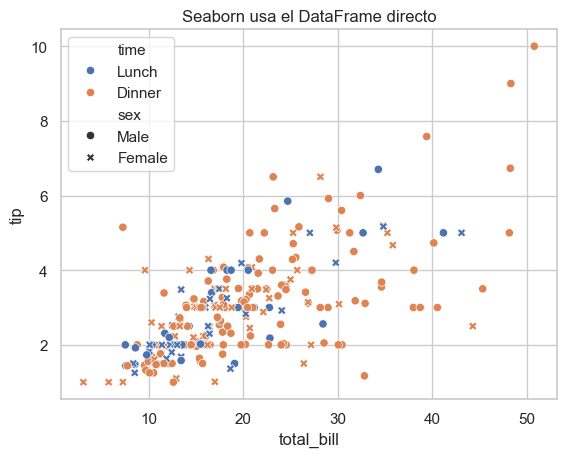

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="sex")
plt.title("Seaborn usa el DataFrame directo")
plt.show()

B) Resumen con groupby + reset_index() → barplot

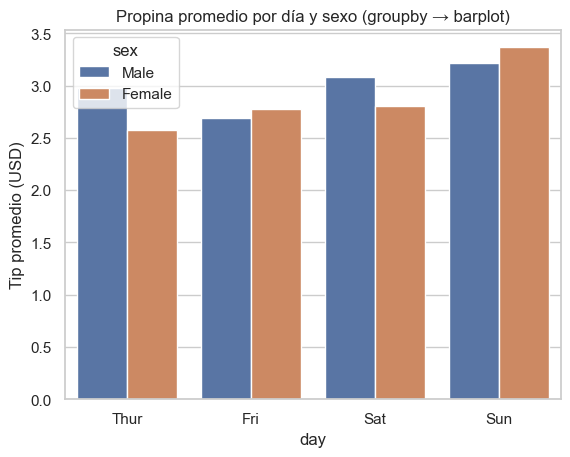

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

# Promedio de propina por día y sexo
resumen = (
    tips.groupby(["day", "sex"], as_index=False)["tip"]
        .mean()
        .rename(columns={"tip": "tip_mean"})
)

sns.barplot(data=resumen, x="day", y="tip_mean", hue="sex", errorbar=None)
plt.title("Propina promedio por día y sexo (groupby → barplot)")
plt.ylabel("Tip promedio (USD)")
plt.show()

C) Wide → Long: melt para graficar varias columnas numéricas en un solo lineplot

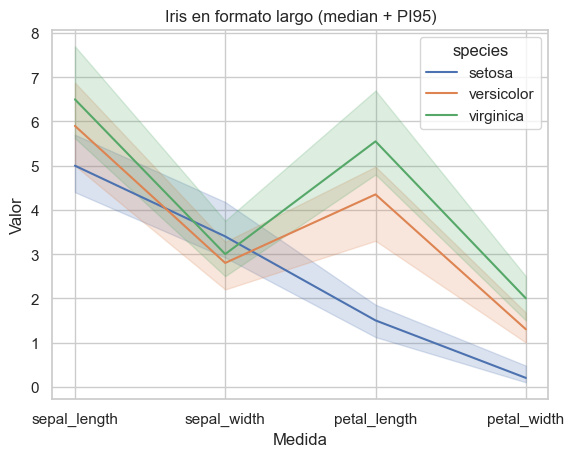

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

iris = sns.load_dataset("iris")

# Pasar de columnas separadas a formato largo (long/tidy)
iris_long = iris.melt(
    id_vars="species",
    value_vars=["sepal_length", "sepal_width", "petal_length", "petal_width"],
    var_name="feature",
    value_name="value"
)

sns.lineplot(data=iris_long, x="feature", y="value", hue="species", estimator="median", errorbar=("pi", 95))
plt.title("Iris en formato largo (median + PI95)")
plt.xlabel("Medida")
plt.ylabel("Valor")
plt.show()

D) Long → Wide: pivot para heatmap (tabla Mes×Año)

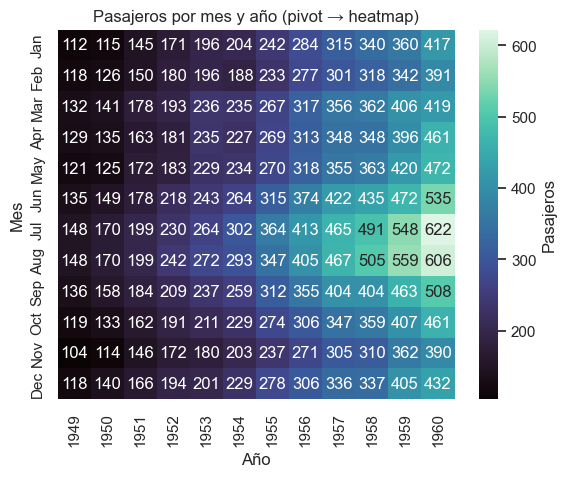

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

flights = sns.load_dataset("flights")  # year, month, passengers
tabla = flights.pivot(index="month", columns="year", values="passengers")

sns.heatmap(tabla, cmap="mako", annot=True, fmt="d", cbar_kws={"label": "Pasajeros"})
plt.title("Pasajeros por mes y año (pivot → heatmap)")
plt.xlabel("Año")
plt.ylabel("Mes")
plt.show()

8.2 Combinar filtros de Pandas con gráficos “dinámicos”
La idea es filtrar con Pandas (boolean masks, query, isin, rangos) y graficar el resultado. Para agilizar sin Jupyter, armamos funciones que aceptan parámetros.

A) Filtros básicos con query / isin + histplot

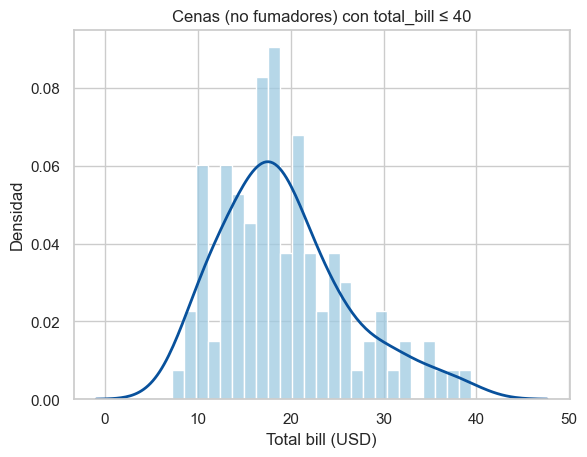

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

# Filtro: solo cenas (Dinner), no fumadores y monto hasta 40 USD
filtro = tips.query("time == 'Dinner' and smoker == 'No' and total_bill <= 40")

sns.histplot(data=filtro, x="total_bill", bins=25, stat="density", color="#9ecae1")
sns.kdeplot(data=filtro, x="total_bill", color="#08519c", linewidth=2)
plt.title("Cenas (no fumadores) con total_bill ≤ 40")
plt.xlabel("Total bill (USD)")
plt.ylabel("Densidad")
plt.show()

B) Función reusable para explorar por parámetros (día, rango y subgrupos)

C:\Users\wiliam\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


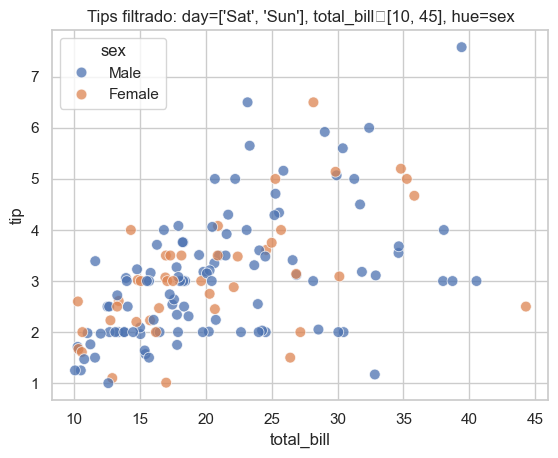

C:\Users\wiliam\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


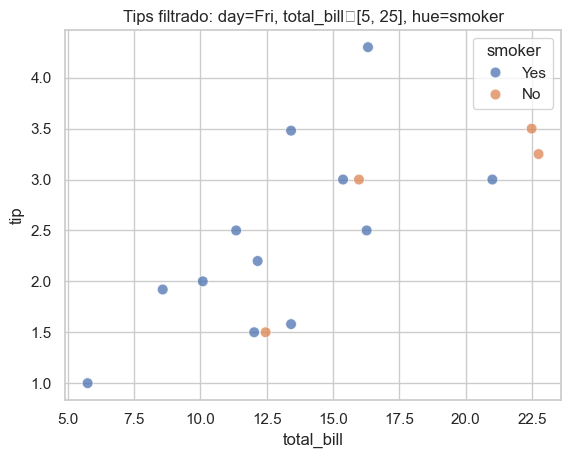

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

def plot_tips(day=None, min_total=None, max_total=None, hue=None):
    df = tips.copy()
    if day:
        df = df[df["day"].isin([day] if isinstance(day, str) else day)]
    if min_total is not None:
        df = df[df["total_bill"] >= min_total]
    if max_total is not None:
        df = df[df["total_bill"] <= max_total]
    # Gráfico
    sns.scatterplot(data=df, x="total_bill", y="tip", hue=hue, alpha=0.75, s=60)
    titulo = f"Tips filtrado: day={day}, total_bill∈[{min_total}, {max_total}], hue={hue}"
    plt.title(titulo)
    plt.show()

# Ejemplos de uso:
plot_tips(day=["Sat", "Sun"], min_total=10, max_total=45, hue="sex")
plot_tips(day="Fri", min_total=5, max_total=25, hue="smoker")

C) Filtros por múltiples categorías y facetas (relplot con col/row)

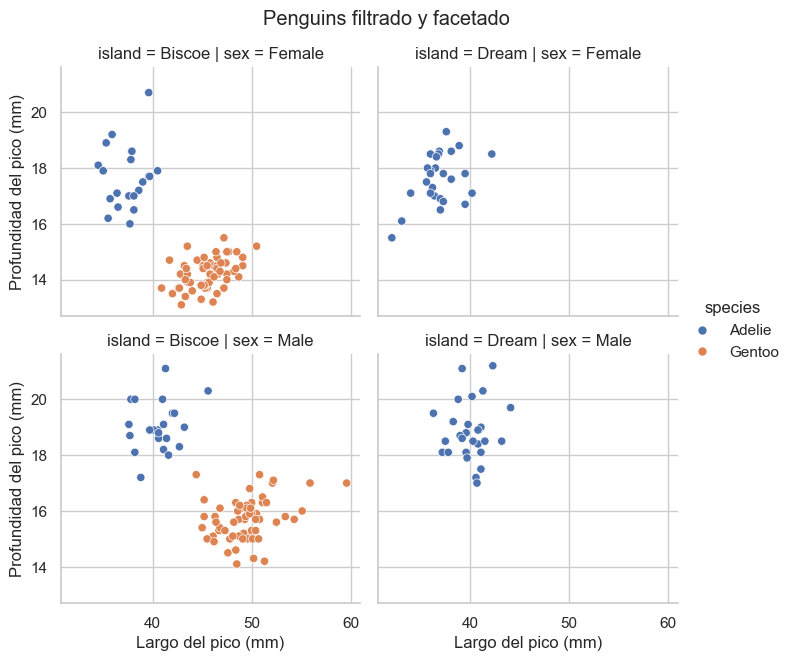

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
penguins = sns.load_dataset("penguins").dropna()

# Filtro: solo especies Adelie y Gentoo, y dos islas
df = penguins.query("species in ['Adelie', 'Gentoo'] and island in ['Biscoe', 'Dream']")

g = sns.relplot(
    data=df, kind="scatter",
    x="bill_length_mm", y="bill_depth_mm",
    hue="species", col="island", row="sex",
    height=3.2, aspect=1.1
)
g.set_axis_labels("Largo del pico (mm)", "Profundidad del pico (mm)")
g.set_titles("island = {col_name} | sex = {row_name}")
g.figure.suptitle("Penguins filtrado y facetado", y=1.03)
plt.show()

D) Filtro y transformación “al vuelo” con .assign() (nueva columna) + violinplot

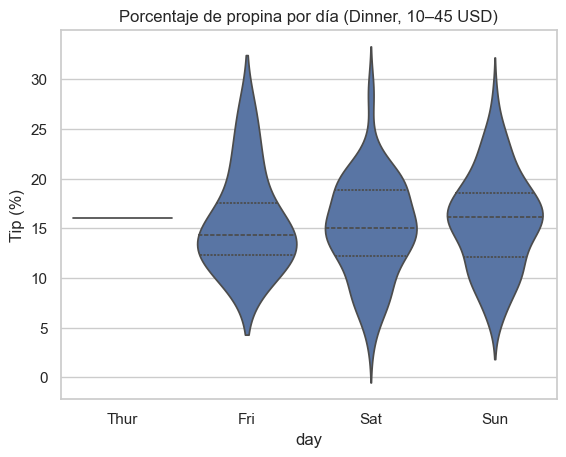

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

# Crear una nueva columna: porcentaje de propina
tips2 = tips.assign(tip_pct = 100 * tips["tip"] / tips["total_bill"])

# Filtro: solo cenas y montos entre 10 y 45 USD
df = tips2.query("time == 'Dinner' and 10 <= total_bill <= 45")

sns.violinplot(data=df, x="day", y="tip_pct", inner="quartile")
plt.title("Porcentaje de propina por día (Dinner, 10–45 USD)")
plt.ylabel("Tip (%)")
plt.show()

E) “Dinámico” con funciones para comparar escenarios (agg + lineplot)

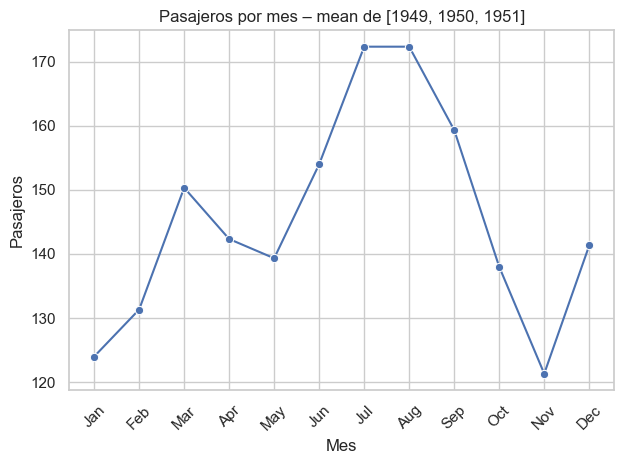

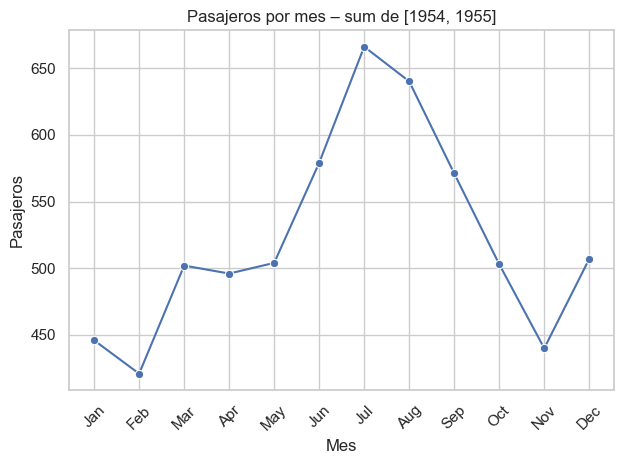

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")
flights = sns.load_dataset("flights")

def plot_flights(years=None, agg="mean"):
    df = flights.copy()
    if years:
        df = df[df["year"].isin(years)]
    # Pivot para tener meses como índice y años como columnas
    tabla = df.pivot(index="month", columns="year", values="passengers")
    # Agregación entre años seleccionados (mean o sum)
    serie = getattr(tabla, agg)(axis=1)
    sns.lineplot(x=serie.index, y=serie.values, marker="o")
    plt.title(f"Pasajeros por mes – {agg} de {years if years else 'todos los años'}")
    plt.xlabel("Mes")
    plt.ylabel("Pasajeros")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Ejemplos:
plot_flights(years=[1949, 1950, 1951], agg="mean")
plot_flights(years=[1954, 1955], agg="sum")